Name : Raj Patkar

Roll.no : 23102A0013

Sub : R-Programming

Lab Problem Statement - 05

Install required R packages

In [2]:
install.packages(
  c("igraph", "ggplot2", "dplyr"),
  repos = "https://cloud.r-project.org"
)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Load the libraries

In [3]:
library(igraph)
library(ggplot2)
library(dplyr)


Attaching package: ‘igraph’


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union



Attaching package: ‘dplyr’


The following objects are masked from ‘package:igraph’:

    as_data_frame, groups, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Load the dataset

In [7]:
# --------------------------------------------------
# CREATE SOCIAL NETWORK DATA
# --------------------------------------------------

edges <- data.frame(
  from = c(
    1,1,1,2,2,2,3,3,4,4,
    5,5,6,6,7,7,8,8,9,9,
    10,10,11,11,12,12,13,13,14,15,
    15,16,16,17,18,19
  ),
  to = c(
    2,3,4,3,5,6,4,6,5,7,
    6,8,7,9,8,10,9,11,10,12,
    11,13,12,14,13,15,14,16,17,17,
    18,19,20,20,21,21
  )
)

print(edges)

   from to
1     1  2
2     1  3
3     1  4
4     2  3
5     2  5
6     2  6
7     3  4
8     3  6
9     4  5
10    4  7
11    5  6
12    5  8
13    6  7
14    6  9
15    7  8
16    7 10
17    8  9
18    8 11
19    9 10
20    9 12
21   10 11
22   10 13
23   11 12
24   11 14
25   12 13
26   12 15
27   13 14
28   13 16
29   14 17
30   15 17
31   15 18
32   16 19
33   16 20
34   17 20
35   18 21
36   19 21


In [8]:
# Create graph from edge list

g <- graph_from_data_frame(
  edges,
  directed = FALSE
)

g

IGRAPH 6e2d520 UN-- 21 36 -- 
+ attr: name (v/c)
+ edges from 6e2d520 (vertex names):
 [1] 1 --2  1 --3  1 --4  2 --3  2 --5  2 --6  3 --4  3 --6  4 --5  4 --7 
[11] 5 --6  5 --8  6 --7  6 --9  7 --8  7 --10 8 --9  8 --11 9 --10 9 --12
[21] 10--11 10--13 11--12 11--14 12--13 12--15 13--14 13--16 14--17 15--17
[31] 15--18 16--19 16--20 17--20 18--21 19--21

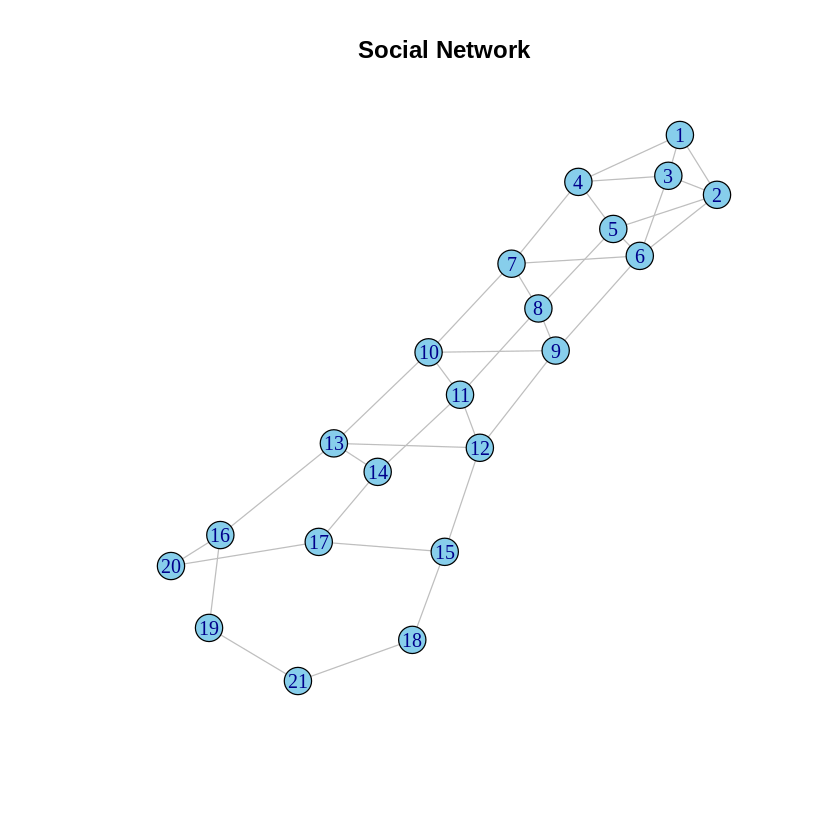

In [9]:
plot(
  g,
  layout = layout_with_fr(g),
  vertex.size = 10,
  vertex.color = "skyblue",
  vertex.label = V(g)$name,
  vertex.frame.color = "black",
  edge.color = "gray",
  main = "Social Network"
)

In [10]:
g

IGRAPH 6e2d520 UN-- 21 36 -- 
+ attr: name (v/c)
+ edges from 6e2d520 (vertex names):
 [1] 1 --2  1 --3  1 --4  2 --3  2 --5  2 --6  3 --4  3 --6  4 --5  4 --7 
[11] 5 --6  5 --8  6 --7  6 --9  7 --8  7 --10 8 --9  8 --11 9 --10 9 --12
[21] 10--11 10--13 11--12 11--14 12--13 12--15 13--14 13--16 14--17 15--17
[31] 15--18 16--19 16--20 17--20 18--21 19--21

Examine the network

In [11]:
cat("Number of nodes:", vcount(g), "\n")
cat("Number of edges:", ecount(g), "\n")

Number of nodes: 21 
Number of edges: 36 


In [12]:
V(g)

+ 21/21 vertices, named, from 6e2d520:
 [1] 1  2  3  4  5  6  7  8  9  10 11 12 13 14 15 16 17 18 19 20 21

In [13]:
E(g)

+ 36/36 edges from 6e2d520 (vertex names):
 [1] 1 --2  1 --3  1 --4  2 --3  2 --5  2 --6  3 --4  3 --6  4 --5  4 --7 
[11] 5 --6  5 --8  6 --7  6 --9  7 --8  7 --10 8 --9  8 --11 9 --10 9 --12
[21] 10--11 10--13 11--12 11--14 12--13 12--15 13--14 13--16 14--17 15--17
[31] 15--18 16--19 16--20 17--20 18--21 19--21

Display node names

In [14]:
V(g)$label <- 1:vcount(g)

Basic network visualization

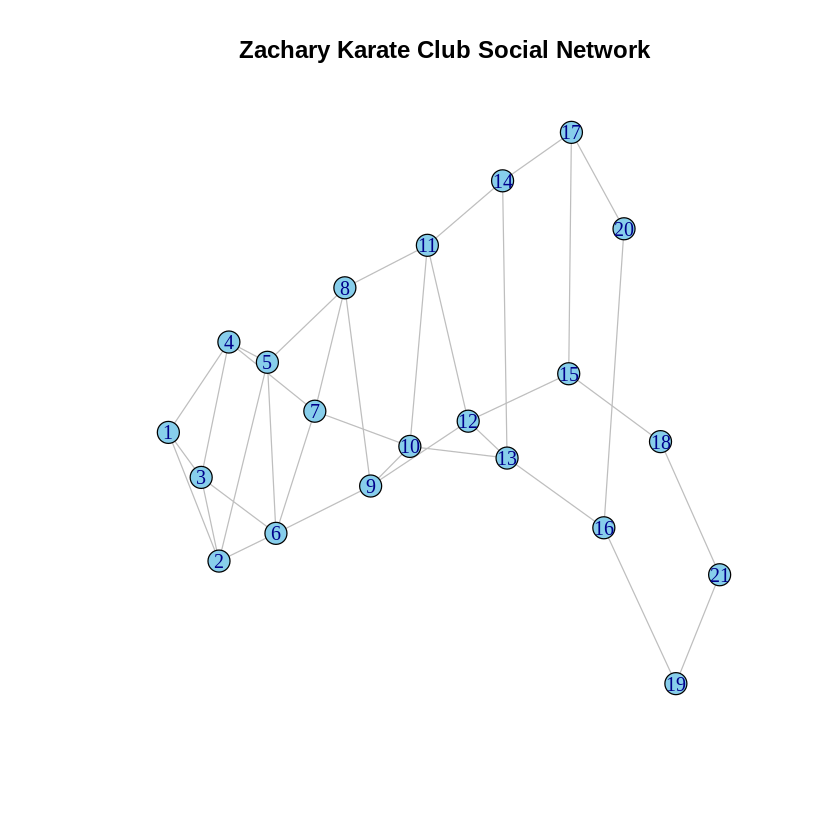

In [15]:
plot(
  g,
  vertex.label = V(g)$label,
  vertex.size = 8,
  vertex.color = "skyblue",
  vertex.frame.color = "black",
  edge.color = "gray",
  main = "Zachary Karate Club Social Network"
)

Calculate Degree Centrality

In [16]:
degree_values <- degree(g)

degree_values

1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 
 3  4  4  4  4  5  4  4  4  4  4  4  4  3  3  3  3  2  2  2  2

In [17]:
degree_table <- data.frame(
  Node = 1:vcount(g),
  Degree = degree_values
)

degree_table

,Node,Degree
,<int>,<dbl>
1,1,3
2,2,4
3,3,4
4,4,4
5,5,4
6,6,5
7,7,4
8,8,4
9,9,4


Find the most connected nodes

In [18]:
degree_table %>%
  arrange(desc(Degree))

,Node,Degree
,<int>,<dbl>
6,6,5
2,2,4
3,3,4
4,4,4
5,5,4
7,7,4
8,8,4
9,9,4
10,10,4


In [19]:
most_connected <- degree_table %>%
  arrange(desc(Degree)) %>%
  slice(1)

most_connected

,Node,Degree
,<int>,<dbl>
6,6,5


In [20]:
cat(
  "Most connected node:",
  most_connected$Node,
  "\nDegree:",
  most_connected$Degree
)

Most connected node: 6 
Degree: 5

Betweenness Centrality

In [21]:
betweenness_values <- betweenness(
  g,
  directed = FALSE,
  normalized = TRUE
)

betweenness_values

1           2           3           4           5           6 
0.001754386 0.026704261 0.021629073 0.070827068 0.054795322 0.179887218 
          7           8           9          10          11          12 
0.152142857 0.117756892 0.217272348 0.197151211 0.129047619 0.244390142 
         13          14          15          16          17          18 
0.228834586 0.069548872 0.170714286 0.158684211 0.056228070 0.064035088 
         19          20          21 
0.041228070 0.013157895 0.015789474

In [22]:
betweenness_table <- data.frame(
  Node = 1:vcount(g),
  Betweenness = betweenness_values
)

betweenness_table %>%
  arrange(desc(Betweenness))

,Node,Betweenness
,<int>,<dbl>
12,12,0.244390142
13,13,0.228834586
9,9,0.217272348
10,10,0.197151211
6,6,0.179887218
15,15,0.170714286
16,16,0.158684211
7,7,0.152142857
11,11,0.129047619


In [23]:
highest_betweenness <- betweenness_table %>%
  arrange(desc(Betweenness)) %>%
  slice(1)

highest_betweenness

,Node,Betweenness
,<int>,<dbl>
12,12,0.2443901


Closeness Centrality

In [24]:
closeness_values <- closeness(
  g,
  mode = "all",
  normalized = TRUE
)

closeness_values

1         2         3         4         5         6         7         8 
0.2631579 0.3030303 0.2898551 0.3076923 0.3225806 0.3636364 0.3773585 0.3773585 
        9        10        11        12        13        14        15        16 
0.4166667 0.4166667 0.4000000 0.4255319 0.4081633 0.3571429 0.3571429 0.3333333 
       17        18        19        20        21 
0.3278689 0.2857143 0.2702703 0.2857143 0.2500000

In [25]:
closeness_table <- data.frame(
  Node = 1:vcount(g),
  Closeness = closeness_values
)

closeness_table %>%
  arrange(desc(Closeness))

,Node,Closeness
,<int>,<dbl>
12,12,0.4255319
9,9,0.4166667
10,10,0.4166667
13,13,0.4081633
11,11,0.4000000
7,7,0.3773585
8,8,0.3773585
6,6,0.3636364
14,14,0.3571429


In [26]:
highest_closeness <- closeness_table %>%
  arrange(desc(Closeness)) %>%
  slice(1)

highest_closeness

,Node,Closeness
,<int>,<dbl>
12,12,0.4255319


Eigenvector Centrality

In [27]:
eigen_values <- eigen_centrality(
  g,
  directed = FALSE
)$vector

eigen_values

1          2          3          4          5          6          7 
0.61088941 0.82683530 0.81309038 0.77038412 0.83836069 1.00000000 0.77726763 
         8          9         10         11         12         13         14 
0.71059531 0.69002072 0.58578808 0.49805786 0.42614489 0.34592444 0.24259621 
        15         16         17         18         19         20         21 
0.14738350 0.11034155 0.11319917 0.04216855 0.03278033 0.05665606 0.01899568

In [28]:
eigen_table <- data.frame(
  Node = 1:vcount(g),
  Eigenvector = eigen_values
)

eigen_table %>%
  arrange(desc(Eigenvector))

,Node,Eigenvector
,<int>,<dbl>
6,6,1.00000000
5,5,0.83836069
2,2,0.82683530
3,3,0.81309038
7,7,0.77726763
4,4,0.77038412
8,8,0.71059531
9,9,0.69002072
1,1,0.61088941


In [29]:
highest_eigen <- eigen_table %>%
  arrange(desc(Eigenvector)) %>%
  slice(1)

highest_eigen

,Node,Eigenvector
,<int>,<dbl>
6,6,1


Combine all centrality measures

In [30]:
centrality_table <- data.frame(
  Node = 1:vcount(g),
  Degree = degree(g),
  Betweenness = betweenness(
    g,
    directed = FALSE,
    normalized = TRUE
  ),
  Closeness = closeness(
    g,
    mode = "all",
    normalized = TRUE
  ),
  Eigenvector = eigen_centrality(
    g,
    directed = FALSE
  )$vector
)

centrality_table

,Node,Degree,Betweenness,Closeness,Eigenvector
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,3,0.001754386,0.2631579,0.61088941
2,2,4,0.026704261,0.3030303,0.82683530
3,3,4,0.021629073,0.2898551,0.81309038
4,4,4,0.070827068,0.3076923,0.77038412
5,5,4,0.054795322,0.3225806,0.83836069
6,6,5,0.179887218,0.3636364,1.00000000
7,7,4,0.152142857,0.3773585,0.77726763
8,8,4,0.117756892,0.3773585,0.71059531
9,9,4,0.217272348,0.4166667,0.69002072


In [31]:
centrality_table %>%
  arrange(desc(Degree))

,Node,Degree,Betweenness,Closeness,Eigenvector
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
6,6,5,0.179887218,0.3636364,1.00000000
2,2,4,0.026704261,0.3030303,0.82683530
3,3,4,0.021629073,0.2898551,0.81309038
4,4,4,0.070827068,0.3076923,0.77038412
5,5,4,0.054795322,0.3225806,0.83836069
7,7,4,0.152142857,0.3773585,0.77726763
8,8,4,0.117756892,0.3773585,0.71059531
9,9,4,0.217272348,0.4166667,0.69002072
10,10,4,0.197151211,0.4166667,0.58578808


Display top 10 influential nodes

In [32]:
top_nodes <- centrality_table %>%
  arrange(desc(Degree)) %>%
  slice_head(n = 10)

top_nodes

,Node,Degree,Betweenness,Closeness,Eigenvector
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
6,6,5,0.17988722,0.3636364,1.0000000
2,2,4,0.02670426,0.3030303,0.8268353
3,3,4,0.02162907,0.2898551,0.8130904
4,4,4,0.07082707,0.3076923,0.7703841
5,5,4,0.05479532,0.3225806,0.8383607
7,7,4,0.15214286,0.3773585,0.7772676
8,8,4,0.11775689,0.3773585,0.7105953
9,9,4,0.21727235,0.4166667,0.6900207
10,10,4,0.19715121,0.4166667,0.5857881


Calculate network density

In [33]:
network_density <- edge_density(g)

cat("Network Density:", network_density, "\n")

Network Density: 0.1714286 


Calculate network diameter

In [34]:
network_diameter <- diameter(
  g,
  directed = FALSE
)

cat("Network Diameter:", network_diameter, "\n")

Network Diameter: 7 


Calculate average path length

In [35]:
average_path <- mean_distance(
  g,
  directed = FALSE
)

cat("Average Path Length:", average_path, "\n")

Average Path Length: 3.019048 


Check whether the network is connected

In [36]:
is_connected(g)

[1] TRUE

In [37]:
if (is_connected(g)) {
  cat("The network is connected.\n")
} else {
  cat("The network contains multiple disconnected components.\n")
}

The network is connected.


Find connected components

In [38]:
components_result <- components(g)

components_result

$membership
 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 
 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 

$csize
[1] 21

$no
[1] 1

In [39]:
cat(
  "Number of connected components:",
  components_result$no,
  "\n"
)

Number of connected components: 1 


Improve the network visualization using degree

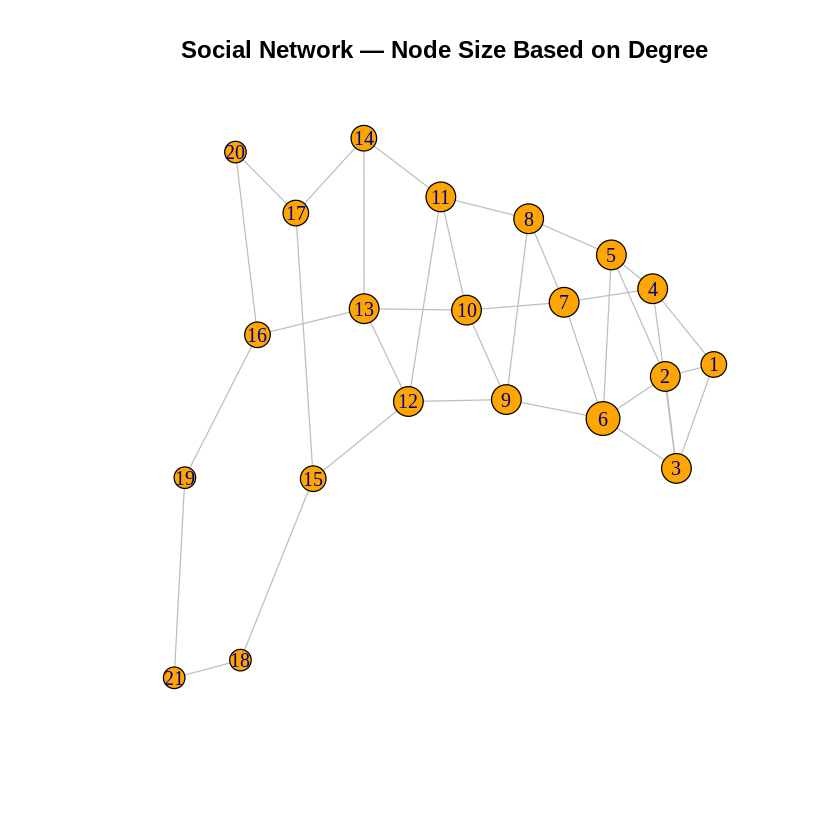

In [40]:
node_degree <- degree(g)

plot(
  g,
  vertex.label = 1:vcount(g),
  vertex.size = 5 + node_degree * 1.5,
  vertex.color = "orange",
  vertex.frame.color = "black",
  edge.color = "gray",
  main = "Social Network — Node Size Based on Degree"
)

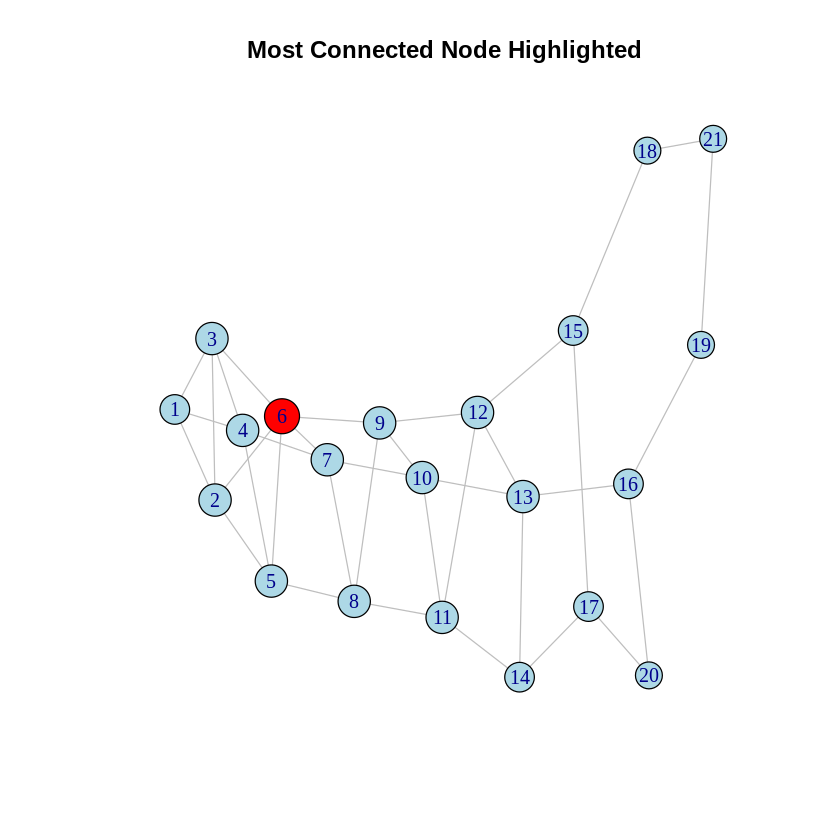

In [41]:
max_degree <- max(degree(g))

node_colors <- ifelse(
  degree(g) == max_degree,
  "red",
  "lightblue"
)

plot(
  g,
  vertex.label = 1:vcount(g),
  vertex.color = node_colors,
  vertex.size = 8 + degree(g),
  edge.color = "gray",
  main = "Most Connected Node Highlighted"
)

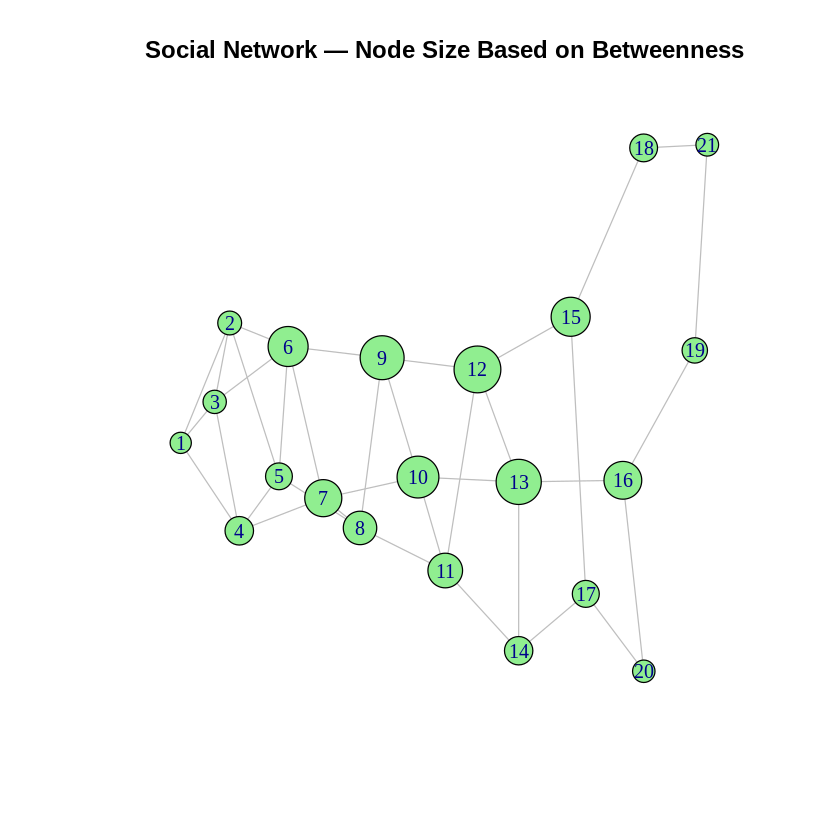

In [42]:
bt <- betweenness(
  g,
  directed = FALSE,
  normalized = TRUE
)

plot(
  g,
  vertex.label = 1:vcount(g),
  vertex.size = 8 + bt * 40,
  vertex.color = "lightgreen",
  vertex.frame.color = "black",
  edge.color = "gray",
  main = "Social Network — Node Size Based on Betweenness"
)

In [43]:
centrality_table %>%
  arrange(desc(Degree)) %>%
  head(10)

,Node,Degree,Betweenness,Closeness,Eigenvector
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
6,6,5,0.17988722,0.3636364,1.0000000
2,2,4,0.02670426,0.3030303,0.8268353
3,3,4,0.02162907,0.2898551,0.8130904
4,4,4,0.07082707,0.3076923,0.7703841
5,5,4,0.05479532,0.3225806,0.8383607
7,7,4,0.15214286,0.3773585,0.7772676
8,8,4,0.11775689,0.3773585,0.7105953
9,9,4,0.21727235,0.4166667,0.6900207
10,10,4,0.19715121,0.4166667,0.5857881


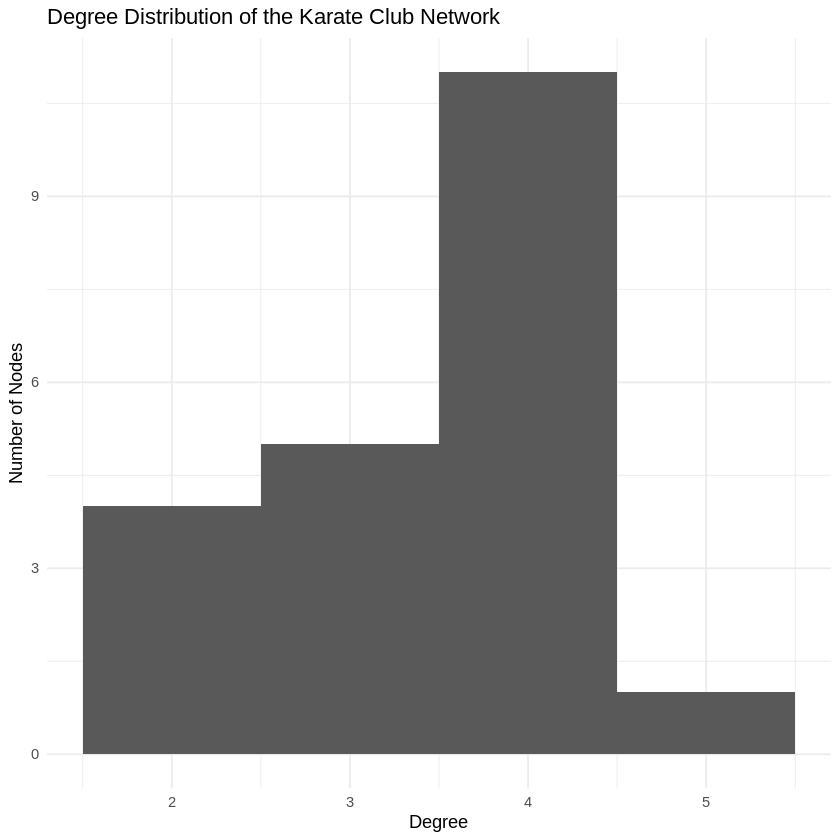

In [44]:
degree_df <- data.frame(
  Node = 1:vcount(g),
  Degree = degree(g)
)

ggplot(
  degree_df,
  aes(x = Degree)
) +
  geom_histogram(
    binwidth = 1,
    boundary = 0.5
  ) +
  labs(
    title = "Degree Distribution of the Karate Club Network",
    x = "Degree",
    y = "Number of Nodes"
  ) +
  theme_minimal()

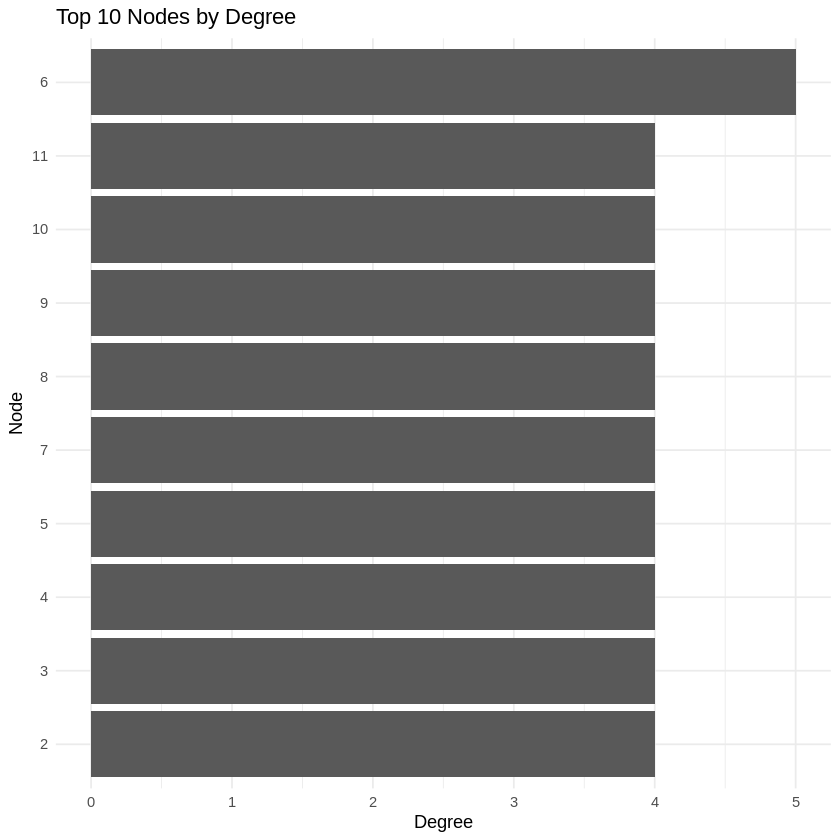

In [45]:
top_degree <- degree_df %>%
  arrange(desc(Degree)) %>%
  slice_head(n = 10)

ggplot(
  top_degree,
  aes(
    x = reorder(as.factor(Node), Degree),
    y = Degree
  )
) +
  geom_col() +
  labs(
    title = "Top 10 Nodes by Degree",
    x = "Node",
    y = "Degree"
  ) +
  coord_flip() +
  theme_minimal()

In [46]:
cat("====================================\n")
cat("SOCIAL NETWORK ANALYSIS SUMMARY\n")
cat("====================================\n")

cat("Number of Nodes:", vcount(g), "\n")
cat("Number of Edges:", ecount(g), "\n")
cat("Network Density:", edge_density(g), "\n")
cat("Network Diameter:", diameter(g), "\n")
cat("Average Path Length:", mean_distance(g), "\n")
cat("Connected Network:", is_connected(g), "\n")

cat("\nMost Connected Node:\n")
print(
  centrality_table %>%
    arrange(desc(Degree)) %>%
    slice(1)
)

cat("\nHighest Betweenness Node:\n")
print(
  centrality_table %>%
    arrange(desc(Betweenness)) %>%
    slice(1)
)

cat("\nHighest Closeness Node:\n")
print(
  centrality_table %>%
    arrange(desc(Closeness)) %>%
    slice(1)
)

cat("\nHighest Eigenvector Centrality Node:\n")
print(
  centrality_table %>%
    arrange(desc(Eigenvector)) %>%
    slice(1)
)

SOCIAL NETWORK ANALYSIS SUMMARY
Number of Nodes: 21 
Number of Edges: 36 
Network Density: 0.1714286 
Network Diameter: 7 
Average Path Length: 3.019048 
Connected Network: TRUE 

Most Connected Node:
  Node Degree Betweenness Closeness Eigenvector
6    6      5   0.1798872 0.3636364           1

Highest Betweenness Node:
   Node Degree Betweenness Closeness Eigenvector
12   12      4   0.2443901 0.4255319   0.4261449

Highest Closeness Node:
   Node Degree Betweenness Closeness Eigenvector
12   12      4   0.2443901 0.4255319   0.4261449

Highest Eigenvector Centrality Node:
  Node Degree Betweenness Closeness Eigenvector
6    6      5   0.1798872 0.3636364           1


In [47]:
# Verify graph exists
stopifnot(is_igraph(g))

# Verify number of nodes
stopifnot(vcount(g) > 0)

# Verify number of edges
stopifnot(ecount(g) > 0)

# Verify degree values
stopifnot(length(degree(g)) == vcount(g))

# Verify betweenness values
stopifnot(length(betweenness(g)) == vcount(g))

# Verify closeness values
stopifnot(length(closeness(g)) == vcount(g))

# Verify eigenvector values
stopifnot(
  length(eigen_centrality(g)$vector) == vcount(g)
)

cat("All tests passed successfully!\n")

All tests passed successfully!
